# Лабораторная работа № 8. Снижение размерности. Метод главных компонент. Анализ независимых компонент

**Тема:** «Разработка программного продукта бота для определения сорта стекла»

**Исходные данные:** Kaggle — [uciml/glass](https://www.kaggle.com/uciml/glass) (Glass Identification Data Set: 214 образцов стекла, 9 признаков — показатель преломления RI и содержание оксидов Na, Mg, Al, Si, K, Ca, Ba, Fe; целевая переменная `Type` — сорт стекла).

## Цель работы
Применить методы снижения размерности PCA, FastICA и t-SNE к масштабированным данным о стекле, проанализировать объяснённую дисперсию и сравнить представления.

## 1. Теоретическая часть

**1. Что такое снижение размерности и зачем оно нужно?** Преобразование данных из пространства многих признаков в пространство меньшей размерности с сохранением максимума информации. Нужно для визуализации, ускорения обучения, борьбы с шумом, мультиколлинеарностью и «проклятием размерности».

**2. Идея PCA.** Найти новые ортогональные оси (главные компоненты) — линейные комбинации исходных признаков, вдоль которых дисперсия данных максимальна. Первые компоненты несут наибольшую долю изменчивости; остальные отбрасываются.

**3. Дисперсия и её роль в PCA.** Дисперсия — мера информативности направления: чем больше разброс вдоль оси, тем больше различий между объектами она передаёт. PCA ранжирует компоненты по объяснённой дисперсии, поэтому масштаб признаков критичен.

**4. ICA и PCA.** PCA ищет некоррелированные компоненты с максимальной дисперсией (цель — компактное представление). ICA ищет статистически *независимые* источники, из смеси которых образованы данные (цель — разделение источников, «слепое разделение сигналов»); компоненты не упорядочены по дисперсии и не обязательно ортогональны.

**5. Почему после масштабирования?** PCA и ICA чувствительны к масштабу: признак с большими значениями (Si) будет доминировать в дисперсии и определит главные компоненты независимо от своей информативности.

## 2. Практическая часть

In [ ]:
import os, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown
warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 160)
sns.set_theme(style="whitegrid")

URL  = "https://archive.ics.uci.edu/ml/machine-learning-databases/glass/glass.data"
COLS = ["Id", "RI", "Na", "Mg", "Al", "Si", "K", "Ca", "Ba", "Fe", "Type"]
FEATURES = ["RI", "Na", "Mg", "Al", "Si", "K", "Ca", "Ba", "Fe"]
TYPE_NAMES = {1: "окна зданий (float)", 2: "окна зданий (non-float)",
              3: "окна авто (float)", 5: "контейнеры",
              6: "посуда", 7: "фары"}

def load_glass():
    """Набор Kaggle uciml/glass (glass.csv). Если файл не загружен в Colab,
    берём тот же набор из репозитория UCI."""
    if os.path.exists("glass.csv"):
        return pd.read_csv("glass.csv")
    return pd.read_csv(URL, names=COLS).drop(columns="Id")

df = load_glass()

# ---------- сквозной пайплайн подготовки данных (ЛР 5-7) ----------
from sklearn.preprocessing import StandardScaler
from sklearn.feature_selection import SelectKBest, f_classif, RFE, SelectFromModel
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

def clean_glass(d):
    """ЛР 5: пропуски, допустимые пределы, дубликаты."""
    d = d.copy()
    d = d.dropna()
    ok = d[["Na", "Mg", "Al", "Si", "K", "Ca", "Ba", "Fe"]].apply(lambda s: s.between(0, 100)).all(axis=1)
    ok &= d["RI"].between(1.3, 1.7)
    return d[ok].drop_duplicates().reset_index(drop=True)

def scale_glass(d):
    """ЛР 6: стандартизация признаков (целевая Type не масштабируется)."""
    s = d.copy()
    s[FEATURES] = StandardScaler().fit_transform(d[FEATURES])
    return s

def select_glass(s):
    """ЛР 7: три метода отбора (фильтр, обёртка, встроенный) + голосование >= 2."""
    X, y = s[FEATURES], s["Type"]
    f1 = set(X.columns[SelectKBest(f_classif, k=6).fit(X, y).get_support()])
    f2 = set(X.columns[RFE(LogisticRegression(max_iter=2000), n_features_to_select=6).fit(X, y).get_support()])
    f3 = set(X.columns[SelectFromModel(RandomForestClassifier(n_estimators=300, random_state=42), threshold="median").fit(X, y).get_support()])
    votes = {f: (f in f1) + (f in f2) + (f in f3) for f in FEATURES}
    keep = [f for f in FEATURES if votes[f] >= 2]
    return s[keep + ["Type"]], keep

clean  = clean_glass(df)
scaled = scale_glass(clean)

X = scaled[FEATURES].values; y = scaled['Type'].values
print('Входная (масштабированная) выборка:', scaled.shape)

Входная (масштабированная) выборка: (213, 10)


### 2.1. Базовый уровень — PCA

Размерность: было (213, 9) -> стало (213, 2)
Объяснённая дисперсия компонент: [0.279 0.229] | сумма: 0.508


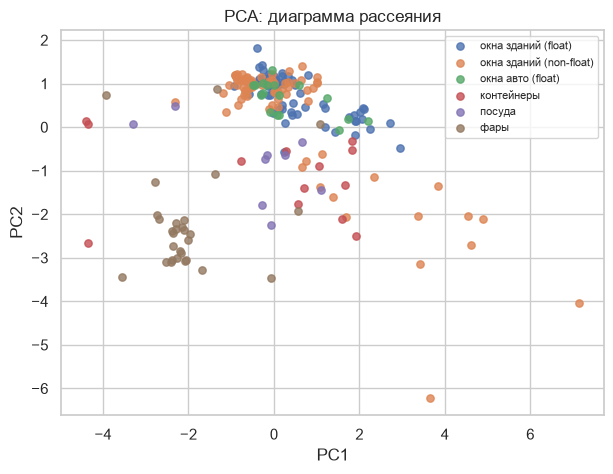

Пропуски: 0


In [ ]:
from sklearn.decomposition import PCA, FastICA
pca2 = PCA(n_components=2, random_state=42)
Z2 = pca2.fit_transform(X)
print("Размерность: было", X.shape, "-> стало", Z2.shape)
print("Объяснённая дисперсия компонент:", pca2.explained_variance_ratio_.round(3), "| сумма:", pca2.explained_variance_ratio_.sum().round(3))
plt.figure(figsize=(7, 5))
for t in np.unique(y):
    plt.scatter(Z2[y == t, 0], Z2[y == t, 1], label=TYPE_NAMES[t], s=28, alpha=.8)
plt.xlabel("PC1"); plt.ylabel("PC2"); plt.title("PCA: диаграмма рассеяния"); plt.legend(fontsize=8); plt.show()
print("Пропуски:", int(np.isnan(Z2).sum()))

**Ответ.** Выбрано 2 компоненты (для визуализации); размерность снижена с 9 до 2. Пропусков нет, данные готовы к дальнейшему анализу.

### 2.2. Объяснённая дисперсия, FastICA

PC,PC1,PC2,PC3,PC4,PC5,PC6,PC7,PC8,PC9
доля,0.279,0.229,0.156,0.127,0.102,0.059,0.041,0.007,0.0
накопленная,0.279,0.508,0.664,0.791,0.893,0.952,0.993,1.000,1.0


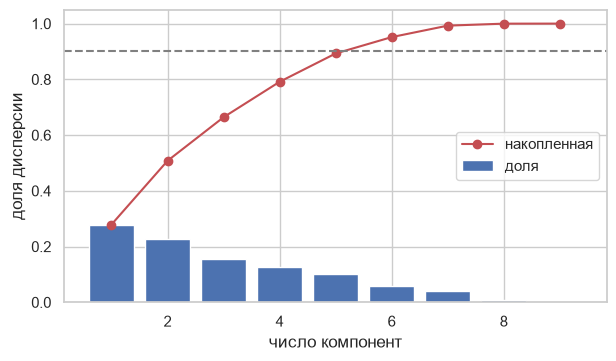

Для сохранения 80% дисперсии нужно компонент: 5
Для сохранения 90% дисперсии нужно компонент: 6
Для сохранения 95% дисперсии нужно компонент: 6
k=2: сохранено 50.8% дисперсии
k=3: сохранено 66.4% дисперсии
k=5: сохранено 89.3% дисперсии
k=7: сохранено 99.3% дисперсии


In [ ]:
pca = PCA(random_state=42).fit(X)
evr = pca.explained_variance_ratio_; cum = evr.cumsum()
display(pd.DataFrame({"PC": [f"PC{i+1}" for i in range(len(evr))], "доля": evr.round(3), "накопленная": cum.round(3)}).set_index("PC").T)
fig, ax = plt.subplots(figsize=(7, 3.8))
ax.bar(range(1, len(evr) + 1), evr, label="доля"); ax.plot(range(1, len(evr) + 1), cum, "o-r", label="накопленная")
ax.axhline(0.9, color="gray", ls="--"); ax.set_xlabel("число компонент"); ax.set_ylabel("доля дисперсии"); ax.legend(); plt.show()
for thr in (0.8, 0.9, 0.95):
    print(f"Для сохранения {int(thr*100)}% дисперсии нужно компонент: {int(np.searchsorted(cum, thr) + 1)}")
for k in (2, 3, 5, 7):
    print(f"k={k}: сохранено {cum[k-1]*100:.1f}% дисперсии")

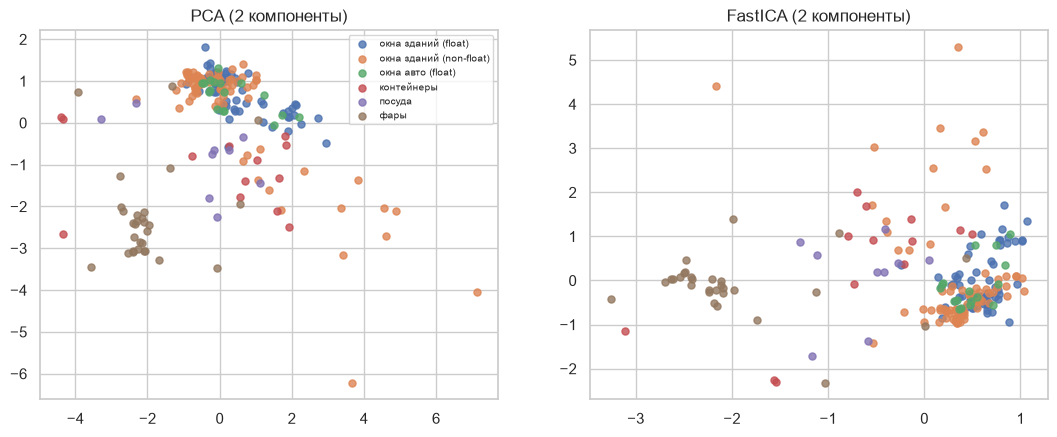

Корреляция компонент PCA: 0.0 | ICA: 0.0
Вклад признаков в компоненты PCA:


,RI,Na,Mg,Al,Si,K,Ca,Ba,Fe
PC1,0.54,-0.27,0.11,-0.43,-0.22,-0.22,0.49,-0.25,0.19
PC2,-0.29,-0.27,0.59,-0.30,0.16,0.15,-0.35,-0.48,0.06


In [ ]:
ica = FastICA(n_components=2, random_state=42, max_iter=1000)
Zi = ica.fit_transform(X)
fig, ax = plt.subplots(1, 2, figsize=(13, 4.8))
for a, (t, Z) in zip(ax, [("PCA (2 компоненты)", Z2), ("FastICA (2 компоненты)", Zi)]):
    for k in np.unique(y):
        a.scatter(Z[y == k, 0], Z[y == k, 1], label=TYPE_NAMES[k], s=26, alpha=.8)
    a.set_title(t)
ax[0].legend(fontsize=7); plt.show()
print("Корреляция компонент PCA:", np.corrcoef(Z2.T)[0, 1].round(3), "| ICA:", np.corrcoef(Zi.T)[0, 1].round(3))
print("Вклад признаков в компоненты PCA:"); display(pd.DataFrame(pca2.components_, columns=FEATURES, index=["PC1", "PC2"]).round(2))

**Ответы.** Для сохранения 90 % дисперсии достаточно 6 компонент (точные значения — в выводе выше), 2 компоненты сохраняют лишь около 51 % — данные «многомерны», сильного сжатия без потерь нет. Разумным можно считать 6–7 компонент для моделирования и 2 — для визуализации. FastICA на тех же данных даёт 2 *независимые* компоненты: в отличие от PCA они не упорядочены по дисперсии, не ортогональны, а их оси развёрнуты в направлениях, выделяющих отдельные «источники» (например, барий-содержащие фары).

### 2.3. Сравнение PCA, ICA, t-SNE

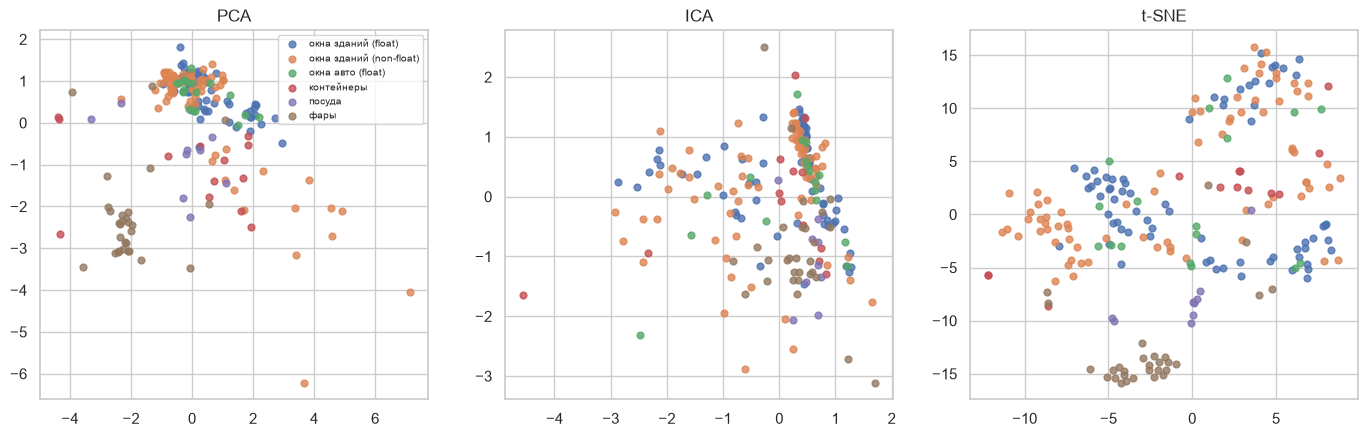

,представление,размерность,kNN accuracy (CV),silhouette по классам
0,Исходные (9 признаков),9,0.652,-0.033
1,PCA (6 компонент),6,0.666,-0.037
2,ICA (6 компонент),6,0.633,-0.042
3,t-SNE (2 компоненты),2,0.690,-0.035


In [ ]:
from sklearn.manifold import TSNE
from sklearn.model_selection import cross_val_score, StratifiedKFold
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import silhouette_score
Zp = PCA(n_components=6, random_state=42).fit_transform(X)
Zic = FastICA(n_components=6, random_state=42, max_iter=2000).fit_transform(X)
Zt = TSNE(n_components=2, random_state=42, perplexity=30, init="pca").fit_transform(X)
fig, ax = plt.subplots(1, 3, figsize=(17, 4.8))
for a, (t, Z) in zip(ax, [("PCA", Zp[:, :2]), ("ICA", Zic[:, :2]), ("t-SNE", Zt)]):
    for k in np.unique(y):
        a.scatter(Z[y == k, 0], Z[y == k, 1], s=24, alpha=.8, label=TYPE_NAMES[k])
    a.set_title(t)
ax[0].legend(fontsize=7); plt.show()
cv = StratifiedKFold(5, shuffle=True, random_state=42)
rows = []
for name, Z in [("Исходные (9 признаков)", X), ("PCA (6 компонент)", Zp), ("ICA (6 компонент)", Zic), ("t-SNE (2 компоненты)", Zt)]:
    acc = cross_val_score(KNeighborsClassifier(5), Z, y, cv=cv).mean()
    rows.append([name, Z.shape[1], round(acc, 3), round(silhouette_score(Z, y), 3)])
display(pd.DataFrame(rows, columns=["представление", "размерность", "kNN accuracy (CV)", "silhouette по классам"]))

**Ответы.** *Размерность:* исходные данные — 9 признаков, PCA/ICA — 6, t-SNE — 2. *Характер компонент:* PCA — линейные, ортогональные, упорядочены по дисперсии; ICA — линейные, статистически независимые; t-SNE — нелинейное вложение, сохраняет локальные соседства, но оси не имеют смысла, а метод не переносится на новые данные. *Интерпретируемость:* лучше всего у PCA (можно смотреть веса признаков), у ICA — средняя, у t-SNE — только визуальная. PCA предпочтителен для сжатия, борьбы с мультиколлинеарностью и ускорения моделей; ICA — когда нужно выделить независимые источники сигнала; t-SNE — для разведочной визуализации кластеров.

### Вывод

Снижение размерности расположено в пайплайне после очистки, кодирования, масштабирования (и, при необходимости, отбора признаков) и перед обучением моделей. Входом служит стандартизованная выборка, поскольку PCA и ICA чувствительны к масштабу: без него доминировал бы кремний. PCA показал, что первые две компоненты объясняют около половины общей дисперсии, а для 90 % требуется порядка шести компонент, то есть информация о составе стекла распределена по многим направлениям, и сильное сжатие невозможно без потерь. Поэтому для моделирования разумно оставить 6–7 компонент, а двумерное представление использовать для визуализации. FastICA даёт независимые компоненты и полезен для выделения признаков отдельных сортов, но его компоненты менее интерпретируемы, а t-SNE годится только для визуального анализа кластеров. Проверка kNN в кросс-валидации показывает, что 6 компонент PCA дают точность 0.666 против 0.652 на исходных девяти признаках (то есть качество не теряется), ICA с шестью компонентами — 0.633, t-SNE — 0.690 (он используется только для визуализации и не применим к новым данным). Силуэтные коэффициенты по классам отрицательны во всех представлениях — классы стекла перекрываются, что объясняет умеренную точность на уровне 65–70 %. Следовательно, сниженная по размерности выборка сохраняет существенную информацию и пригодна для дальнейшего моделирования. Вместе с тем в последующих лабораторных (ЛР 9–12) используется выборка после отбора признаков, так как она сохраняет интерпретируемость исходных оксидов — важное требование для бота, объясняющего свой ответ. PCA-представление при этом остаётся запасным вариантом для ускорения и визуализации. Все преобразования выполнены с фиксированным `random_state`, поэтому результаты воспроизводимы.